# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [1]:
import pandas as pd

brut = pd.read_csv("donnees/consommation_brut.csv")

print("Forme :", brut.shape)
print("\nTypes :")
print(brut.dtypes)
print("\nManquants par colonne :")
print(brut.isna().sum())
print("\nLignes en double :", brut.duplicated().sum())

Forme : (300, 4)

Types :
mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object

Manquants par colonne :
mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64

Lignes en double : 12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [2]:
print("Écritures différentes de quartier :", brut["quartier"].nunique())
print("\nListe complète :")
print(sorted(brut["quartier"].unique()))

Écritures différentes de quartier : 43

Liste complète :
[' Bas-Peu-de-Chose', ' Carénage', ' Delmas 33', ' Delmas 65', ' Delmas 75', ' Morne Calvaire', ' Petite-Anse', ' Place Saint-Pierre', ' Thomassin', 'BAS-PEU-DE-CHOSE', 'BOIS-VERNA', 'Bas-Peu-de-Chose', 'Bas-Peu-de-Chose ', 'Bois-Verna', 'CARÉNAGE', 'CENTRE-VILLE', 'Carénage', 'Carénage ', 'Centre-ville', 'Centre-ville ', 'DELMAS 33', 'Delmas 33', 'Delmas 33 ', 'Delmas 65', 'Delmas 75', 'Delmas 75 ', 'Morne Calvaire', 'PLACE SAINT-PIERRE', 'Petite-Anse', 'Place Saint-Pierre', 'Place Saint-Pierre ', 'RUE 15', 'Rue 15', 'Rue 15 ', 'THOMASSIN', 'Thomassin', 'Thomassin ', 'bas-peu-de-chose', 'carénage', 'centre-ville', 'delmas 65', 'delmas 75', 'place saint-pierre']


**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [3]:
texte_kwh = brut["kwh"]
en_nombre = pd.to_numeric(texte_kwh, errors="coerce")

valeurs_invalides = texte_kwh[en_nombre.isna() & texte_kwh.notna()]
print("Valeurs de kwh non convertibles en nombre :")
print(valeurs_invalides)

Valeurs de kwh non convertibles en nombre :
0      184410 kWh
4      206280 kWh
9      215140 kWh
13        251 900
21     274520 kWh
27     301740 kWh
36     233010 kWh
43     155930 kWh
51     212510 kWh
53     424110 kWh
55     299610 kWh
58        373 880
59     333670 kWh
62     597730 kWh
66     456060 kWh
69     495020 kWh
72        409 300
82        556 070
88     260360 kWh
89     260360 kWh
104    347870 kWh
105       408 780
109       364 090
116    243160 kWh
138       154 720
139       154 720
154       233 700
171       253 300
182    385840 kWh
190    445270 kWh
194       337 810
195       366 390
204       154 740
207    170420 kWh
213    201690 kWh
214    201690 kWh
226     81370 kWh
228    139470 kWh
229     77670 kWh
230    139230 kWh
231    139230 kWh
235       121 240
237    160110 kWh
242       105 830
260    163010 kWh
264    198720 kWh
271       281 240
273       104 640
277    166700 kWh
284        73 110
292       171 160
297    187230 kWh
Name: kwh, dtype: st

## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [4]:
propre = brut.copy()

propre["kwh"] = propre["kwh"].str.replace(" kWh", "", regex=False).str.replace(" ", "", regex=False)
propre["kwh"] = pd.to_numeric(propre["kwh"], errors="coerce")

print("Manquants dans kwh après conversion :", propre["kwh"].isna().sum())
print("Type de la colonne kwh :", propre["kwh"].dtype)

Manquants dans kwh après conversion : 9
Type de la colonne kwh : float64


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [5]:
quartiers = pd.read_csv("donnees/quartiers.csv")

officiels = {nom.lower(): nom for nom in quartiers["quartier"]}
propre["quartier"] = propre["quartier"].str.strip().str.lower().map(officiels)

print("Quartiers distincts après harmonisation :", propre["quartier"].nunique())
print("Noms non reconnus (NaN) :", propre["quartier"].isna().sum())
print(sorted(propre["quartier"].dropna().unique()))

Quartiers distincts après harmonisation : 12
Noms non reconnus (NaN) : 0
['Bas-Peu-de-Chose', 'Bois-Verna', 'Carénage', 'Centre-ville', 'Delmas 33', 'Delmas 65', 'Delmas 75', 'Morne Calvaire', 'Petite-Anse', 'Place Saint-Pierre', 'Rue 15', 'Thomassin']


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [6]:
propre = propre.drop_duplicates()
propre = propre.dropna(subset=["kwh"])

print("Forme après nettoyage :", propre.shape)

Forme après nettoyage : (279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [7]:
for quartier in propre["quartier"].unique():
    du_quartier = propre["quartier"] == quartier
    mediane = propre.loc[du_quartier, "kwh"].median()
    suspect = du_quartier & (propre["kwh"] > 3 * mediane)
    n = suspect.sum()
    if n > 0:
        print(f"{quartier} : {n} valeur(s) divisée(s) par 10")
    propre.loc[suspect, "kwh"] = propre.loc[suspect, "kwh"] / 10

print("\nMaximum de kwh :", propre["kwh"].max())

Delmas 33 : 1 valeur(s) divisée(s) par 10
Delmas 75 : 1 valeur(s) divisée(s) par 10
Morne Calvaire : 1 valeur(s) divisée(s) par 10
Rue 15 : 1 valeur(s) divisée(s) par 10

Maximum de kwh : 742780.0


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [8]:
reference = pd.read_csv("donnees/consommation.csv")

cle = ["mois", "quartier", "kwh", "heures_courant"]

# On aligne sur les lignes présentes dans propre (les 279 sans kwh manquant)
masque = reference.set_index(cle).index.isin(propre.set_index(cle).index)
reference_filtree = reference[masque].reset_index(drop=True)

# On aligne le type kwh (float des deux côtés) et l'ordre
propre = propre.sort_values(cle).reset_index(drop=True)
reference_filtree = reference_filtree.sort_values(cle).reset_index(drop=True)
reference_filtree["kwh"] = reference_filtree["kwh"].astype("float64")

print("Forme propre     :", propre.shape)
print("Forme référence  :", reference_filtree.shape)
print("Nettoyage identique au fichier de référence :",
      propre.equals(reference_filtree[propre.columns]))

Forme propre     : (279, 4)
Forme référence  : (279, 5)
Nettoyage identique au fichier de référence : True


## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [9]:
print("Lignes avant jointure :", propre.shape)

propre = propre.merge(quartiers, on="quartier", how="left")

propre["kwh_par_abonne"] = (propre["kwh"] / propre["abonnes"]).round(1)
propre["annee"] = propre["mois"].str[:4].astype(int)

print("Lignes après jointure :", propre.shape)
print("\nBas-Peu-de-Chose en 2024-01 :")
print(propre.query("quartier == 'Bas-Peu-de-Chose' and mois == '2024-01'")[["quartier", "mois", "kwh", "abonnes", "kwh_par_abonne"]])

Lignes avant jointure : (279, 4)
Lignes après jointure : (279, 9)

Bas-Peu-de-Chose en 2024-01 :
           quartier     mois       kwh  abonnes  kwh_par_abonne
0  Bas-Peu-de-Chose  2024-01  184410.0     2150            85.8


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [10]:
meteo = pd.read_csv("donnees/meteo.csv")

print("Lignes avant jointure météo :", propre.shape)

propre = propre.merge(meteo, on=["mois", "commune"], how="left")

print("Lignes après jointure météo :", propre.shape)
print("Températures manquantes :", propre["temperature_c"].isna().sum())

Lignes avant jointure météo : (279, 9)
Lignes après jointure météo : (279, 11)
Températures manquantes : 0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [11]:
propre.to_csv("donnees/consommation_propre.csv", index=False)

verif = pd.read_csv("donnees/consommation_propre.csv")
print("Forme du fichier propre relu :", verif.shape)
print("Colonnes :", list(verif.columns))

Forme du fichier propre relu : (279, 11)
Colonnes : ['mois', 'quartier', 'kwh', 'heures_courant', 'commune', 'type', 'abonnes', 'kwh_par_abonne', 'annee', 'temperature_c', 'pluie_mm']


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

In [12]:
par_type = propre.groupby("type")["kwh_par_abonne"].mean().round(1)
print("Consommation moyenne par abonné selon le type :")
print(par_type)

print("\nClassement des quartiers :")
classement = (
    propre.groupby("quartier")["kwh_par_abonne"]
    .mean()
    .round(1)
    .sort_values(ascending=False)
)
print(classement)

Consommation moyenne par abonné selon le type :
type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64

Classement des quartiers :
quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64


**Ce qu'on en conclut :**

Les quartiers commerciaux consomment environ 3,3 fois plus par abonné que les quartiers résidentiels (393 kWh contre 117 kWh). Le podium est occupé par Centre-ville (468,7), Place Saint-Pierre (458,3) et Delmas 33 (374,4) : trois quartiers commerciaux, ce qui confirme que l'activité économique pèse plus que la taille du quartier.

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

Consommation totale (millions de kWh) par commune :
annee            2024   2025  hausse_%
commune                               
Delmas          11.61  11.74       1.1
Port-au-Prince  10.09  10.31       2.3
Pétion-Ville     8.60   9.68      12.6
Cap-Haïtien      4.59   5.62      22.5


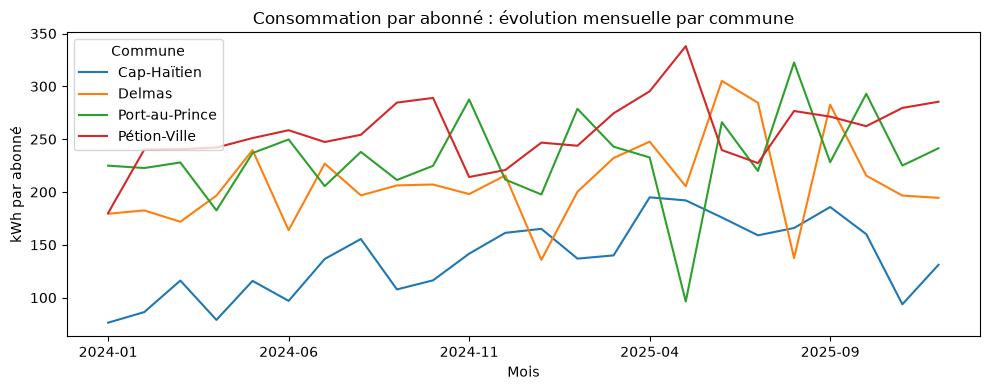

In [13]:
import matplotlib.pyplot as plt

# 1. Consommation totale par commune et par année (colonnes en str pour éviter les surprises)
totaux = propre.pivot_table(index="commune", columns="annee", values="kwh", aggfunc="sum")
totaux.columns = totaux.columns.astype(str)

# 2. Hausse en % sur les valeurs BRUTES (pas arrondies)
totaux["hausse_%"] = ((totaux["2025"] / totaux["2024"] - 1) * 100).round(1)

# 3. Affichage en millions, mais SANS toucher à la hausse déjà calculée
affichage = totaux.copy()
affichage["2024"] = (affichage["2024"] / 1_000_000).round(2)
affichage["2025"] = (affichage["2025"] / 1_000_000).round(2)
print("Consommation totale (millions de kWh) par commune :")
print(affichage.sort_values("2025", ascending=False))

# 4. Courbe
evolution = propre.pivot_table(
    index="mois", columns="commune", values="kwh_par_abonne", aggfunc="mean"
)
ax = evolution.plot(kind="line", figsize=(10, 4))
ax.set_title("Consommation par abonné : évolution mensuelle par commune")
ax.set_xlabel("Mois")
ax.set_ylabel("kWh par abonné")
ax.legend(title="Commune")
plt.tight_layout()
plt.show()

**Ce qu'on en conclut :**

La consommation augmente partout entre 2024 et 2025, mais à des rythmes très inégaux. Cap-Haïtien affiche la plus forte hausse (+22,5 %, de 4,59 à 5,62 millions de kWh), tandis que Delmas stagne (+1,1 %). Sur la courbe mensuelle, les 4 communes suivent la même saisonnalité (pic en mai-juin, creux en juillet-août), mais Cap-Haïtien reste en dessous en valeur absolue par abonné.

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

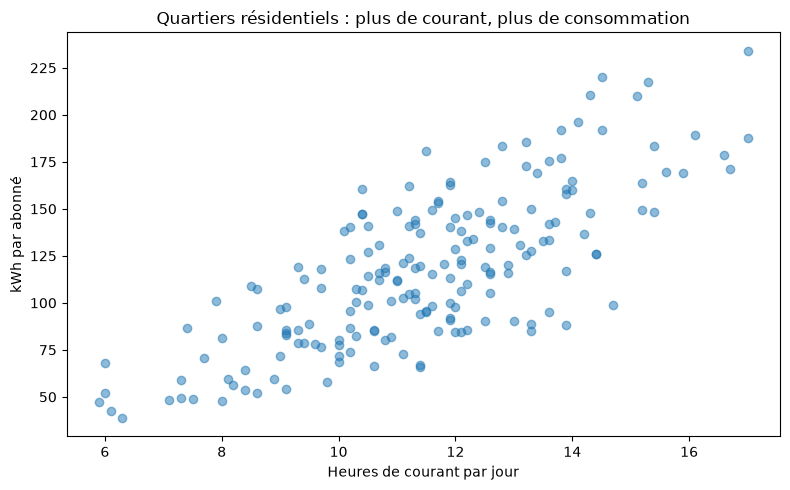

Corrélation kwh_par_abonne / heures_courant  : 0.76
Corrélation kwh_par_abonne / temperature_c  : -0.15


In [14]:
import matplotlib.pyplot as plt

residentiel = propre[propre["type"] == "Résidentiel"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(residentiel["heures_courant"], residentiel["kwh_par_abonne"], alpha=0.5)
ax.set_title("Quartiers résidentiels : plus de courant, plus de consommation")
ax.set_xlabel("Heures de courant par jour")
ax.set_ylabel("kWh par abonné")
plt.tight_layout()
plt.show()

corr_courant = residentiel["kwh_par_abonne"].corr(residentiel["heures_courant"])
corr_chaleur = residentiel["kwh_par_abonne"].corr(residentiel["temperature_c"])

print(f"Corrélation kwh_par_abonne / heures_courant  : {corr_courant:.2f}")
print(f"Corrélation kwh_par_abonne / temperature_c  : {corr_chaleur:.2f}")

**Ce qu'on en conclut :**

Dans les quartiers résidentiels, la consommation par abonné est fortement corrélée aux heures de courant (r = 0,76) et quasiment pas à la température (r = -0,15). Autrement dit : on consomme l'électricité qu'on reçoit, pas en fonction de la chaleur. Le nuage de points montre une tendance montante nette avec les heures de courant.

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

Heures de courant par commune :
                mediane    q1    q3
commune                            
Cap-Haïtien        10.0   8.3  11.7
Delmas             11.9  10.1  13.0
Port-au-Prince     11.6  10.7  13.1
Pétion-Ville       11.6  10.4  13.0


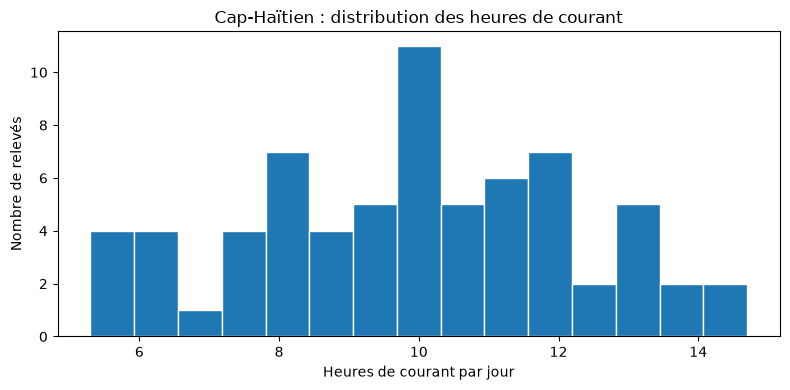


Relevés 2025 avec moins de 8h de courant : 3
        mois   quartier      commune  heures_courant
145  2025-01  Delmas 33       Delmas             7.4
222  2025-08   Carénage  Cap-Haïtien             7.3
265  2025-11     Rue 15  Cap-Haïtien             5.9


In [15]:
import matplotlib.pyplot as plt

# 1. Médiane, Q1, Q3 par commune
stats = propre.groupby("commune")["heures_courant"].agg(
    mediane="median",
    q1=lambda x: x.quantile(0.25),
    q3=lambda x: x.quantile(0.75),
).round(1)
print("Heures de courant par commune :")
print(stats)

# 2. Histogramme pour Cap-Haïtien
cap = propre[propre["commune"] == "Cap-Haïtien"]["heures_courant"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(cap, bins=15, edgecolor="white")
ax.set_title("Cap-Haïtien : distribution des heures de courant")
ax.set_xlabel("Heures de courant par jour")
ax.set_ylabel("Nombre de relevés")
plt.tight_layout()
plt.show()

# 3. Relevés 2025 sous 8h
faibles = propre[(propre["annee"] == 2025) & (propre["heures_courant"] < 8)]
print("\nRelevés 2025 avec moins de 8h de courant :", len(faibles))
print(faibles[["mois", "quartier", "commune", "heures_courant"]])

**Ce qu'on en conclut :**

Cap-Haïtien cumule les coupures les plus longues : médiane de 10,0 heures de courant par jour, contre 11,6 à 11,9 dans les autres communes. Seuls 3 relevés de 2025 descendent sous 8 heures : à Carénage, Delmas 33 et Rue 15. Ces coupures expliquent en partie la plus faible consommation par abonné observée dans ces quartiers.

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [16]:
top3 = propre.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]
print("Les 3 plus grosses consommations :")
print(top3)

Les 3 plus grosses consommations :
        mois      quartier        type       kwh
213  2025-07     Delmas 33  Commercial  742780.0
121  2024-11  Centre-ville  Commercial  597730.0
235  2025-09     Delmas 33  Commercial  591420.0


**Ce qu'on en conclut :**

Les 3 plus grosses consommations du fichier concernent Delmas 33 (2025-07 : 742 780 kWh ; 2025-09 : 591 420 kWh) et Centre-ville (2024-11 : 597 730 kWh). Ce sont 3 quartiers commerciaux, ce qui est cohérent avec leur consommation moyenne par abonné. Aucun de ces pics ne dépasse 3 fois la médiane de son quartier, donc ils ne sont pas des erreurs de saisie.

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

Dans les quartiers résidentiels, la consommation par abonné suit les heures de courant (corrélation de 0,76), pas la température (-0,15) : on consomme l'électricité qu'on reçoit. La plus forte hausse de 2025 est à Cap-Haïtien (+22,5 %), où les coupures restent pourtant les plus longues (médiane de 10,0 heures de courant par jour). Ces corrélations ne prouvent pas une cause : il faudrait des données par abonné et des mois sans coupure pour mesurer l'effet de la chaleur.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.